In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from tqdm import tqdm

In [3]:
import numba

In [4]:
import mctpy as mct
from mctpy.structurefactors import hsm_densities

In [5]:
#qgrid = np.linspace(0.2,39.8,100)
qgrid = np.linspace(0.2,39.9*2,200)

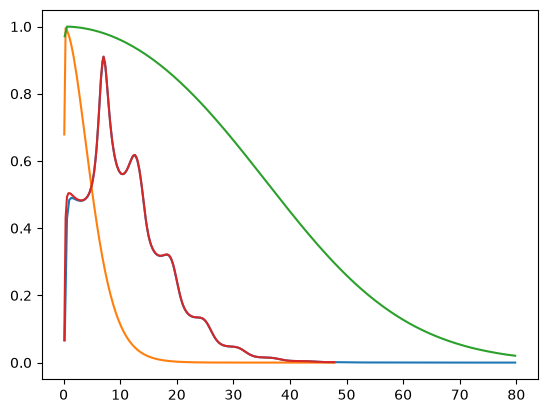

In [6]:
for xb in [0.0,1.0]:
    sq = mct.structurefactors.hsmPY(*hsm_densities([1.0,0.6]).volume_fractions(phi=0.52,xhat=xb))
    model = mct.mixture_model (sq, qgrid)
    nep = mct.nonergodicity_parameter (model = model)
    nep.solve(accuracy=1e-8)
    plt.plot(qgrid, nep.f[:,0,0]/nep.model.sq[:,0,0])
    plt.plot(qgrid*0.6, nep.f[:,1,1]/nep.model.sq[:,1,1])
plt.show()

In [7]:
delta, xb = 0.6, 0.2
d = [1.0, delta]
varphi = [0.5, 0.52]

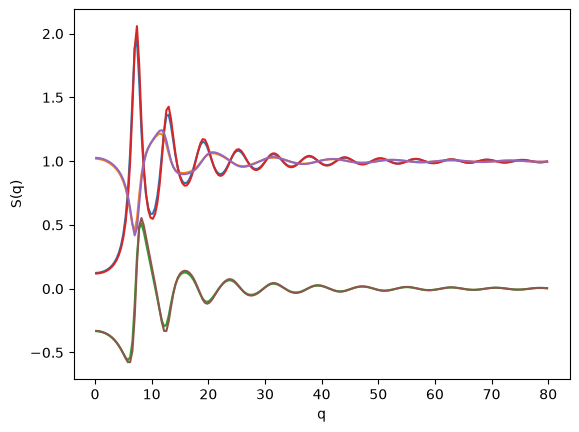

In [8]:
sqlist = []
cslist = []
for packing_fraction in varphi:
    sq = mct.structurefactors.hsmPY(*hsm_densities(d).volume_fractions(phi=packing_fraction, xhat=xb))
    plt.plot(qgrid, sq.Sq(qgrid)[0][:,0,0])
    plt.plot(qgrid, sq.Sq(qgrid)[0][:,1,1])
    plt.plot(qgrid, sq.Sq(qgrid)[0][:,0,1])
    sqlist.append(sq)
plt.xlabel('q')
plt.ylabel('S(q)')
plt.show()

In [9]:
model = mct.mixture_model (sq, qgrid)

In [10]:
nep = mct.nonergodicity_parameter (model = model)
nep.solve(accuracy=1e-8)
nep.converged

True

In [11]:
ev = mct.eigenvalue (nep)
ev.solve()

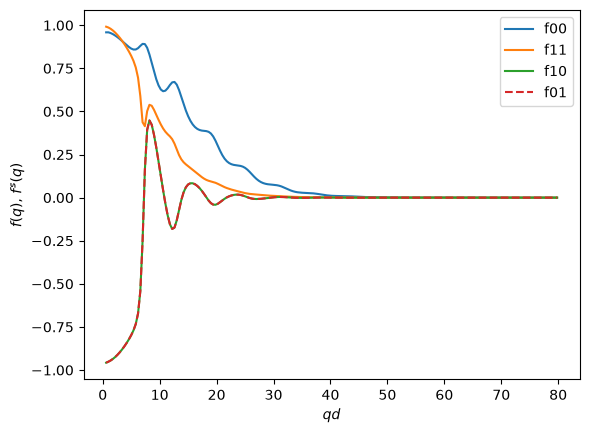

In [12]:
plt.plot(nep.model.q[1:], nep.f[1:,0,0]/nep.model.sq[1:,0,0], label='f00')
plt.plot(nep.model.q[1:], nep.f[1:,1,1]/nep.model.sq[1:,1,1], label='f11')
plt.plot(nep.model.q[1:], nep.f[1:,1,0]/np.sqrt(nep.model.sq[1:,0,0]*nep.model.sq[1:,1,1]), label='f10')
plt.plot(nep.model.q[1:], nep.f[1:,0,1]/np.sqrt(nep.model.sq[1:,0,0]*nep.model.sq[1:,1,1]), label='f01',
        linestyle='dashed')
plt.xlabel(r'$qd$')
plt.ylabel(r'$f(q)$, $f^s(q)$')
plt.legend()
plt.show()

In [13]:
load_from_file = True

class evsearch_hsm:
    def __init__ (self, delta, xbhat):
        self.model = None
        self.delta = delta
        self.xbhat = xbhat
    def calc_ev (self, phi):
        Sq = mct.structurefactors.hsmPY(
            *hsm_densities([1.0,self.delta]).volume_fractions(phi,self.xbhat))
        #Sq = mct.structurefactors.hsmPY([6/np.pi*phi],[1.0]) # this works, same result as HSS
        if self.model is None:
            self.model = mct.mixture_model (Sq, qgrid)
        else:
            self.model.set (Sq=Sq)
        nep = mct.nonergodicity_parameter (model = self.model)
        nep.solve(accuracy=1e-8)
        ev = mct.eigenvalue (nep)
        ev.solve(maxiter=1500)
        return ev

if not load_from_file:
    hsm_c = {}
    for xb in np.linspace(0,1,11):
        phis, evs = mct.util.evscan (0.51, 0.56, evsearch_hsm(delta,xb).calc_ev, eps=1e-6)
        p = np.argmax([ev.eval for ev in evs])
        hsm_c[xb] = {phis[p]: evs[p]}
        print(f"xb = {xb:.2f}  phi_c = {phis[p]:.8f}, lambda = {evs[p].lam:.3f}, ev = {evs[p].eval:.6f}")
    mct.h5.save_file('bhsm-phic.h5', hsm_c)
else:
    hsm_c = mct.h5.load_file('bhsm-phic.h5')
    hsm_c = { float(k):v for k,v in hsm_c.items() }

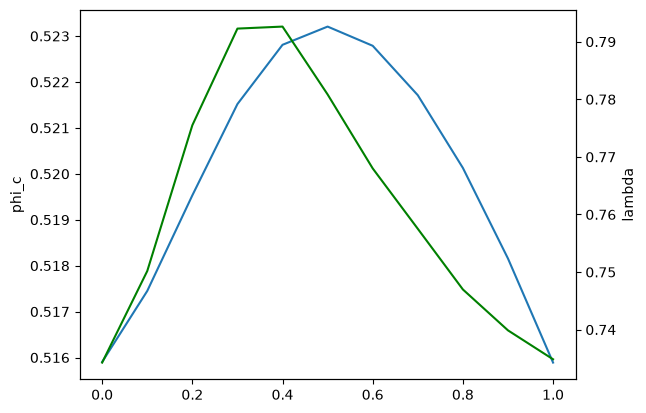

In [14]:
xblist = []
phiclist = []
lamlist = []
for xb, res in hsm_c.items():
    for k,v in res.items():
        phi_c = float(k)
        ev_c = v
    xblist.append(float(xb))
    phiclist.append(phi_c)
    lamlist.append(ev_c.lam)
fig,ax = plt.subplots()
ax.plot(xblist, phiclist, label='phic')
ax2=ax.twinx()
ax2.plot(xblist,lamlist,color='green', label='lambda')
plt.xlabel('xhat')
ax.set_ylabel('phi_c')
ax2.set_ylabel('lambda')
plt.show()

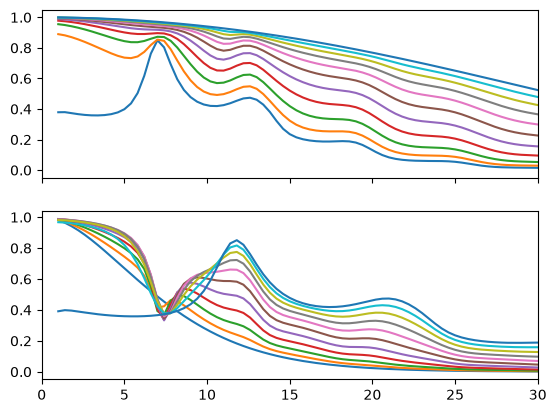

In [15]:
xblist = []
phiclist = []
lamlist = []
fig, ax = plt.subplots(nrows=2, sharex=True)
for xb, res in hsm_c.items():
    for k,v in res.items():
        phi_c = float(k)
        ev_c = v
    for i in range(2):
        ax[i].plot(qgrid[2:], ev_c.nep.f[2:,i,i]/ev_c.nep.model.sq[2:,i,i])
ax[0].set_xlim(0,30)
plt.show()

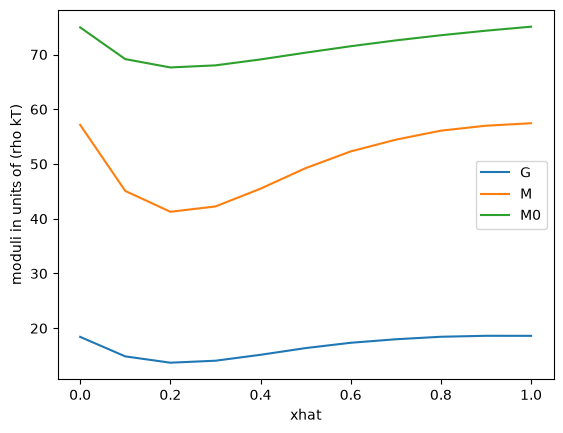

In [16]:
xblist = []
Glist = []
Mlist = []
M0list = []
for xb, res in hsm_c.items():
    for k,v in res.items():
        phi_c = float(k)
        ev_c = v
    xblist.append(float(xb))
    sq = mct.structurefactors.hsmPY(ev_c.nep.model.densities,[1.0,0.6])
    ev_c.nep.model.Sq = sq
    Glist.append(ev_c.nep.model.shear_modulus(ev_c.nep.f,0.))
    Mlist.append(ev_c.nep.model.longitudinal_modulus(ev_c.nep.f,0.))
    M0list.append(np.einsum('a,iab,b',np.sqrt(sq.densities),np.linalg.inv(ev_c.nep.model.sq),np.sqrt(sq.densities))[0]/np.sum(sq.densities)**1)
    lamlist.append(ev_c.lam)
fig,ax = plt.subplots()
ax.plot(xblist, Glist, label='G')
ax.plot(xblist, Mlist, label='M')
ax.plot(xblist, M0list, label='M0')
ax.set_xlabel('xhat')
ax.set_ylabel('moduli in units of (rho kT)')
plt.legend()
plt.show()

In [17]:
sigrange = {}
C = {}
phi_c = {}
for xb, cc in hsm_c.items():
    xb = float(xb)
    phi_c[xb], ev = (*cc.items(),)[0]
    xb = float(xb)
    phi_c[xb] = float(phi_c[xb])
    if xb > 0.2:
        continue
    m1 = mct.mixture_model(mct.structurefactors.hsmPY([0.,0.],d),qgrid)
    phirange = np.linspace(0.51,0.53,51)
    sigrange[xb] = np.zeros_like(phirange)
    for i, phi in enumerate(phirange):
        m1.set (Sq=mct.structurefactors.hsmPY(*hsm_densities(d).volume_fractions(phi=phi, xhat=xb)))
        sigrange[xb][i] = ev.sigma (m1)
    epsrange = (phirange - phi_c[xb]) / phi_c[xb]
    C[xb] = np.interp(0., epsrange, sigrange[xb]/epsrange)

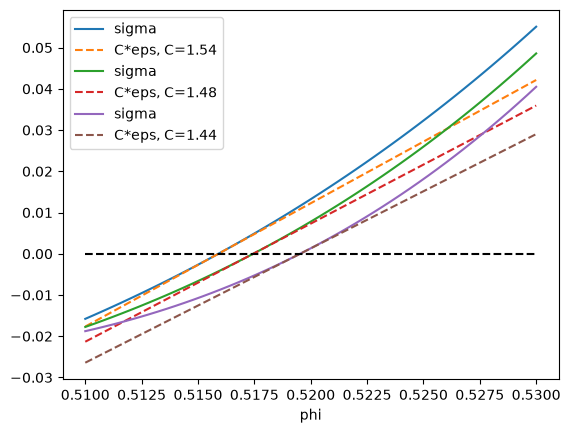

In [18]:
for xbstr in sigrange:
    plt.plot(phirange, sigrange[xbstr], label='sigma')
    plt.plot(phirange, C[xbstr]*(phirange-phi_c[xbstr])/phi_c[xbstr], label=f'C*eps, C={C[xbstr]:.2f}', linestyle='dashed')
plt.plot([phirange[0],phirange[-1]],[0.,0.],linestyle='dashed',color='black')
plt.legend()
plt.xlabel('phi')
plt.show()

In [19]:
load_from_file = True

if not load_from_file:
    correlators = mct.CorrelatorStack()
    packing_fraction = 0.515
    xblist = [0., 0.05, 0.1, 0.2]
    for xb in xblist:
        sq = mct.structurefactors.hsmPY(*hsm_densities(d).volume_fractions(phi=packing_fraction, xhat=xb))
        model = mct.mixture_model (sq, qgrid)
        phi = mct.correlator (model = model, store = True, blocks=50)
        correlators.append(phi)
    correlators.solve_all(progress_bar=tqdm,stop_condition=lambda c:np.isnan(c.phi).any())
    mct.h5.save_file('bhsm-dyn.h5', { xb: phi for xb, phi in zip(xblist,correlators) })

else:
    correlators = mct.CorrelatorStack()
    res = mct.h5.load_file('bhsm-dyn.h5')
    for k,v in res.items():
        correlators.append(v)

In [20]:
qval = 5.4
qi = np.nonzero(np.isclose(qgrid,qval))[0][0]

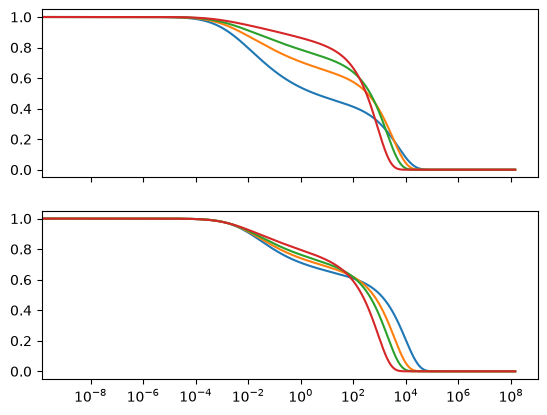

In [21]:
fig, ax = plt.subplots(nrows=2, sharex=True)
for phi in correlators:
    for i in range(2):
        ax[i].plot(phi.t, phi.phi[:,qi,i,i]/phi.phi[0,qi,i,i])
plt.xscale('log')
plt.show()

In [22]:
tagged_correlators = mct.CorrelatorStack()
msds = mct.CorrelatorStack()
for phi in correlators:
    cs = mct.structurefactors.mixtureTagged(phi.model.Sq, 0)
    model_s = mct.mixture_tagged_particle (phi.model, Sq=cs, D0s=1)
    phi_s = mct.correlator (model = model_s, store = True)
    tagged_correlators.append(phi_s)
    model_s0 = mct.tagged_particle_q0 (model_s)
    msd = mct.mean_squared_displacement (model = model_s0, store=True)
    msds.append(msd)

In [23]:
tagged_correlators.solve_all(progress_bar=tqdm)

  0%|                                                   | 0/50 [00:00<?, ?it/s]

  2%|▊                                          | 1/50 [00:04<03:54,  4.78s/it]

  4%|█▋                                         | 2/50 [00:05<01:48,  2.26s/it]

  6%|██▌                                        | 3/50 [00:05<01:08,  1.46s/it]

  8%|███▍                                       | 4/50 [00:06<00:49,  1.08s/it]

 10%|████▎                                      | 5/50 [00:06<00:39,  1.15it/s]

... (43 outputs left out)

 98%|█████████████████████████████████████████▏| 49/50 [00:32<00:00,  1.52it/s]

100%|██████████████████████████████████████████| 50/50 [00:32<00:00,  1.56it/s]

100%|██████████████████████████████████████████| 50/50 [00:32<00:00,  1.52it/s]

np.True_

In [24]:
msds.solve_all(progress_bar=tqdm)

  0%|                                                   | 0/50 [00:00<?, ?it/s]

  2%|▊                                          | 1/50 [00:05<04:15,  5.22s/it]

 16%|██████▉                                    | 8/50 [00:05<00:20,  2.04it/s]

 30%|████████████▌                             | 15/50 [00:05<00:07,  4.51it/s]

 44%|██████████████████▍                       | 22/50 [00:05<00:03,  7.69it/s]

 58%|████████████████████████▎                 | 29/50 [00:05<00:01, 11.67it/s]

 72%|██████████████████████████████▏           | 36/50 [00:05<00:00, 16.44it/s]

 86%|████████████████████████████████████      | 43/50 [00:05<00:00, 21.84it/s]

100%|██████████████████████████████████████████| 50/50 [00:06<00:00, 27.67it/s]

100%|██████████████████████████████████████████| 50/50 [00:06<00:00,  8.31it/s]

np.True_

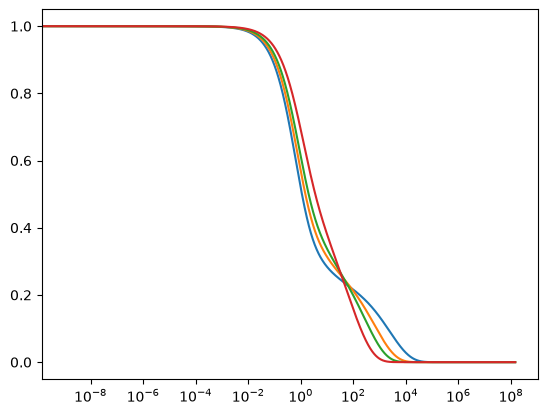

In [25]:
qval = 12.2
qi = np.nonzero(np.isclose(qgrid,qval))[0][0]
for phi_s in tagged_correlators:
    plt.plot(phi_s.t,phi_s.phi[:,qi])
plt.xscale('log')
plt.show()

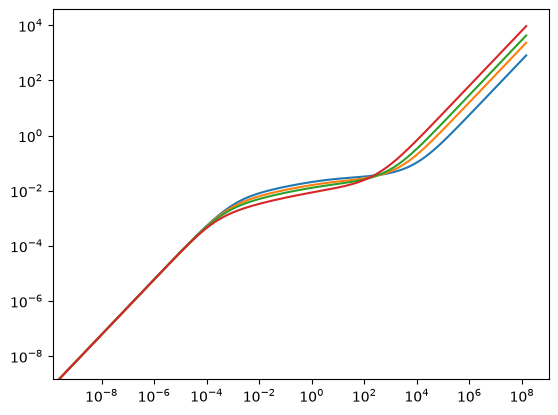

In [26]:
for msd in msds:
    plt.plot(msd.t, msd.phi)
plt.xscale('log')
plt.yscale('log')
plt.show()

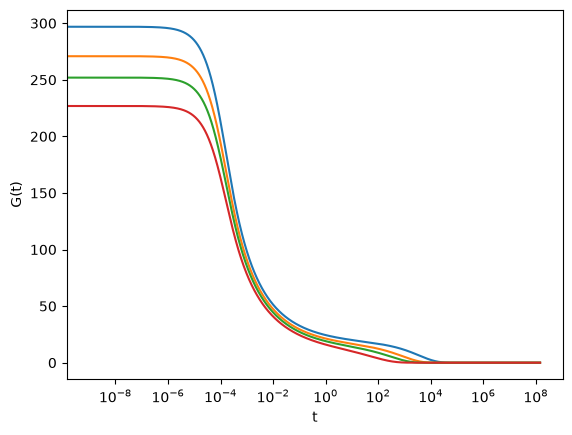

In [27]:
for phi in correlators:
    plt.plot(phi.t,phi.shear_modulus())
plt.xscale('log')
plt.xlabel('t')
plt.ylabel('G(t)')
plt.show()

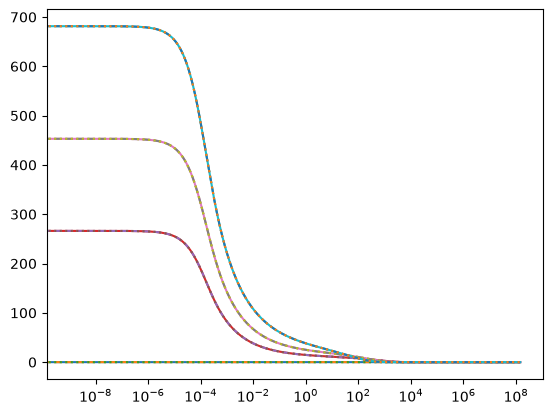

In [28]:
for phi in correlators:
    Mcc = phi.model.cc_modulus(phi.phi,phi.t)
    x = phi.model.densities/phi.model.rho
    plt.plot(phi.t,Mcc[:,0,0]*x[0],linestyle='solid')
    plt.plot(phi.t,Mcc[:,1,1]*x[1],linestyle='dashed')
    plt.plot(phi.t,-Mcc[:,0,1]*np.sqrt(x[0]*x[1]),linestyle='dotted')
plt.xscale('log')
plt.show()

In [29]:
import scipy
for phi in correlators:
    if (phi.model.densities == 0).any():
        continue
    Mcc = phi.model.cc_modulus(phi.phi,phi.t)
    x = phi.model.densities/phi.model.rho
    Laa = x[1]/scipy.integrate.trapezoid(Mcc[:,0,0],x=phi.t)
    Lbb = x[0]/scipy.integrate.trapezoid(Mcc[:,1,1],x=phi.t)
    Lab = -np.sqrt(x[0]*x[1])/scipy.integrate.trapezoid(Mcc[:,0,1],x=phi.t)
    assert np.isclose(Laa,Lab)
    assert np.isclose(Laa,Lbb)
    print("L",Laa)

L 1.9054949561497717e-05


L 3.644160413078282e-05


L 8.93475861162877e-05


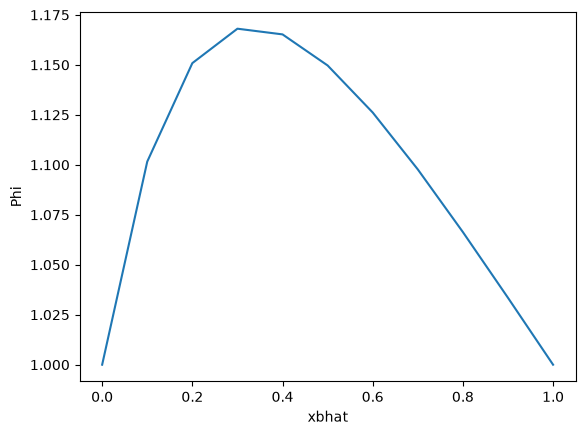

In [30]:
philist = []
xblist = np.linspace(0,1,11)
for xb in xblist:
    sq = mct.structurefactors.hsmPY(*hsm_densities(d).volume_fractions(phi=packing_fraction, xhat=xb))
    x = sq.densities/np.sum(sq.densities)
    s0, _ = sq.Sq(0)
    Phiinv = x[1]*s0[0,0] + x[0]*s0[1,1] - 2*np.sqrt(x[0]*x[1])*s0[0,1]
    philist.append(1./Phiinv)
plt.plot(xblist,philist)
plt.xlabel('xbhat')
plt.ylabel('Phi')
plt.show()